# Análise Exploratória e Explanatória do Dataset: Bitcoin Alpha Trust Weight Signed Network

## Setup de Bibliotecas e Dados

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [10]:
# URL do dataset compactado no site do SNAP
url = "https://snap.stanford.edu/data/soc-sign-bitcoinalpha.csv.gz"

# Carregando o dataset diretamente do link de download
# As colunas originais são: SOURCE, TARGET, RATING, TIME
columns = ["SOURCE", "TARGET", "RATING", "TIME"]
df = pd.read_csv(url, compression="gzip", names=columns)
df.head()

,SOURCE,TARGET,RATING,TIME
0,7188,1,10,1407470400
1,430,1,10,1376539200
2,3134,1,10,1369713600
3,3026,1,10,1350014400
4,3010,1,10,1347854400


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

### Dimensão e Tipos de Dados

In [11]:
df.shape

(24186, 4)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24186 entries, 0 to 24185
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   SOURCE  24186 non-null  int64
 1   TARGET  24186 non-null  int64
 2   RATING  24186 non-null  int64
 3   TIME    24186 non-null  int64
dtypes: int64(4)
memory usage: 755.9 KB


In [13]:
df.describe()

,SOURCE,TARGET,RATING,TIME
count,24186.000000,24186.000000,24186.000000,2.418600e+04
mean,864.029314,1051.093815,1.463946,1.347099e+09
std,1592.085638,1871.765504,2.903656,3.397039e+07
min,1.000000,1.000000,-10.000000,1.289192e+09
25%,58.000000,66.000000,1.000000,1.312690e+09
50%,238.000000,279.000000,1.000000,1.345435e+09
75%,898.000000,1068.000000,2.000000,1.369454e+09
max,7604.000000,7604.000000,10.000000,1.453439e+09


###Duplicadas

In [14]:
df.duplicated().sum()

np.int64(0)

### Criando novas colunas

A coluna TIME está em segundos desde Epoch, então, escolhi transformar para datetime em uma coluna e adicionei mais 6 colunas separando ano, mês, dia, hora, minuto e segundo.

In [15]:
# Convertendo os segundos desde Epoch para datetime (UTC)
df['DATETIME'] = pd.to_datetime(df['TIME'], unit='s', utc=True)

# Criando as 6 colunas adicionais com os valores inteiros correspondentes
df['ANO'] = df['DATETIME'].dt.year
df['MES'] = df['DATETIME'].dt.month
df['DIA'] = df['DATETIME'].dt.day
df['HORA'] = df['DATETIME'].dt.hour
df['MINUTO'] = df['DATETIME'].dt.minute
df['SEGUNDO'] = df['DATETIME'].dt.second

# Visualizando o resultado
df.head()

,SOURCE,TARGET,RATING,TIME,DATETIME,ANO,MES,DIA,HORA,MINUTO,SEGUNDO
0,7188,1,10,1407470400,2014-08-08 04:00:00+00:00,2014,8,8,4,0,0
1,430,1,10,1376539200,2013-08-15 04:00:00+00:00,2013,8,15,4,0,0
2,3134,1,10,1369713600,2013-05-28 04:00:00+00:00,2013,5,28,4,0,0
3,3026,1,10,1350014400,2012-10-12 04:00:00+00:00,2012,10,12,4,0,0
4,3010,1,10,1347854400,2012-09-17 04:00:00+00:00,2012,9,17,4,0,0


## 2. Dados Faltantes

In [16]:
df.isna().sum()

,0
SOURCE,0
TARGET,0
RATING,0
TIME,0
DATETIME,0
ANO,0
MES,0
DIA,0
HORA,0
MINUTO,0


Sem dados faltantes! :)

## 3. Princípio Distribucional

Ainda com os dados originais, vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [17]:
VARS_QUANT = ["RATING", "ANO", "MES", "DIA", "HORA"]
VARS_QUALI = ["SOURCE", "TARGET"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
RATING,1.46,1.00,2.90,-10.00,10.00,-1.35,7.64
ANO,2012.20,2012.00,1.07,2010.00,2016.00,0.45,-0.62
MES,6.34,6.00,3.09,1.00,12.00,0.21,-0.82
DIA,15.39,15.00,8.80,1.00,31.00,0.06,-1.20
HORA,4.27,4.00,0.44,4.00,5.00,1.04,-0.91


**`RATING`**: Apresenta **assimetria negativa significativa (~ -1.35)** e uma **curtose extremamente alta (~ 7.64)**. Isso indica que a distribuição das notas é bastante assimétrica (concentrada em valores altos/positivos) e possui **caudas pesadas** (presença de valores extremos, tanto muito positivos quanto muito negativos).

**`ANO`, `MES`, `DIA` e `HORA`**: Apresentam tanto assimetria quanto curtose próximas de zero ou em módulo menores que 1, comportando-se de forma muito mais uniforme e simétrica no dataset.



**Isso é totalmente coerente.** Em redes de confiança e reputação de criptomoedas como o *Bitcoin Alpha*, é altamente esperado que:
1. A grande maioria das transações e avaliações seja positiva (com notas concentradas em $+1$ ou superiores) para indicar que os membros da comunidade confiam uns nos outros, gerando a assimetria negativa.
2. Exista uma cauda pesada com avaliações severamente negativas (como $-10$). Essas notas extremas funcionam como alertas ou denúncias de fraudes e comportamentos desonestos, gerando o alto valor de curtose (cauda pesada), o que reflete a dinâmica real de um sistema de avaliação de risco.

### Distribuições de dados

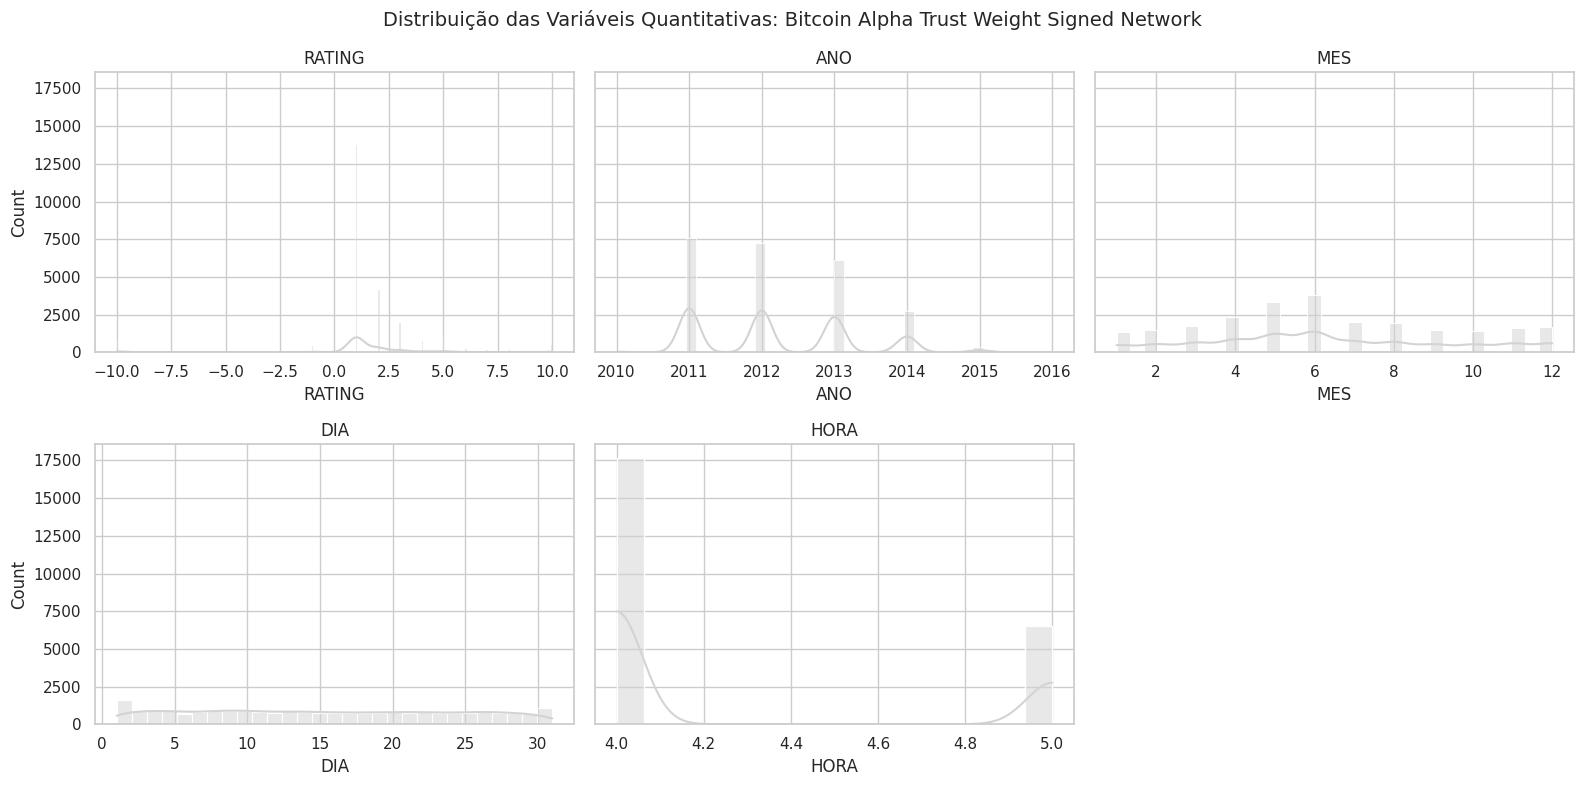

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Bitcoin Alpha Trust Weight Signed Network", fontsize=14)
plt.tight_layout()
plt.show()

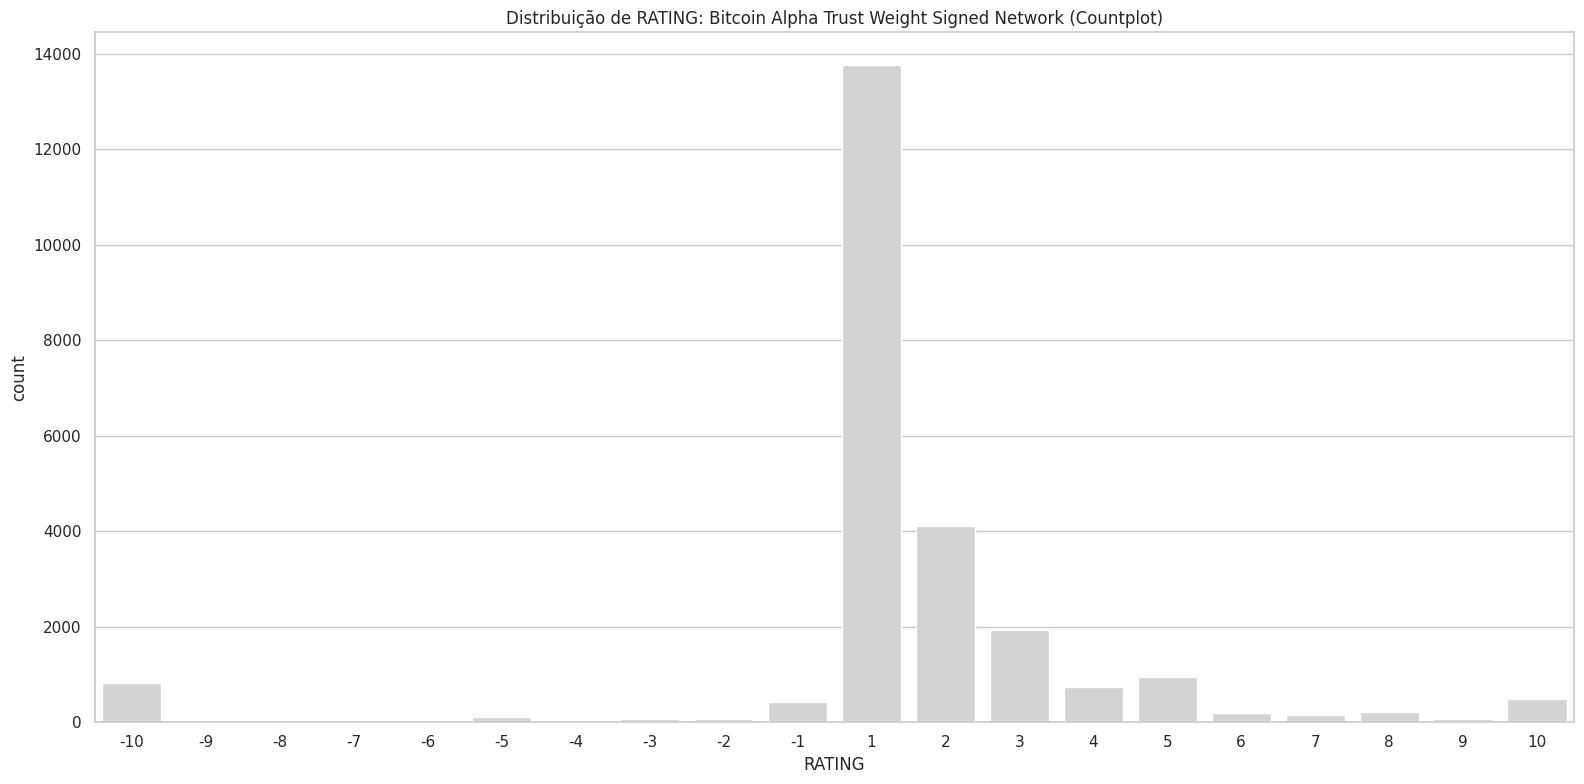

In [19]:
fig, ax = plt.subplots(figsize=(16, 8))

# Usando countplot para mostrar as contagens das notas discretas de RATING
sns.countplot(data=df, x="RATING", color=COR_NEUTRA, ax=ax)

ax.set_title("Distribuição de RATING: Bitcoin Alpha Trust Weight Signed Network (Countplot)")
plt.tight_layout()
plt.show()

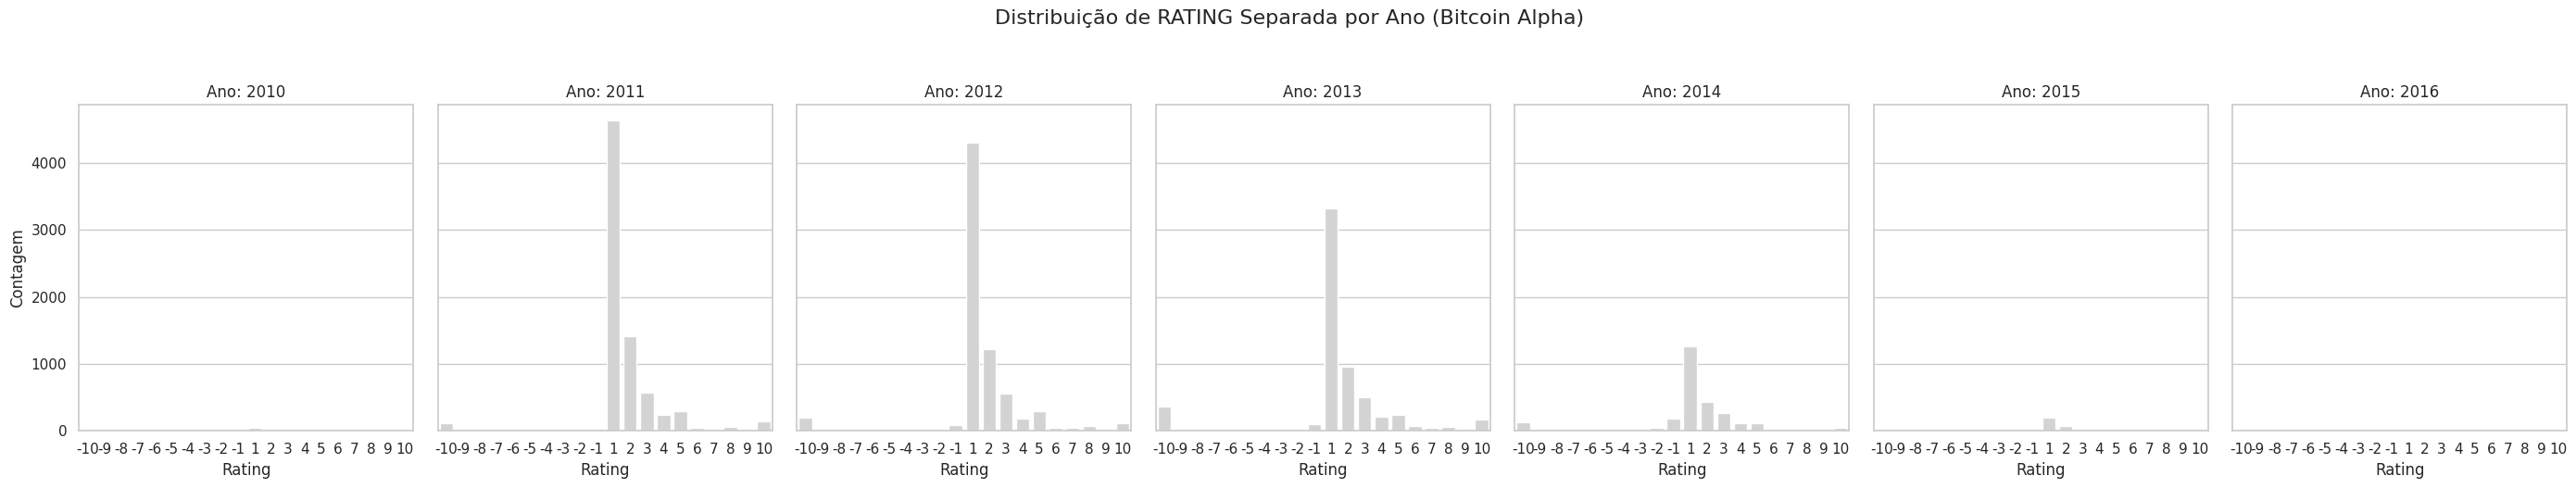

In [20]:
anos_unicos = sorted(df["ANO"].unique())
num_anos = len(anos_unicos)

# Criando uma grade de subplots (uma linha de gráficos, ou múltiplas se necessário)
fig, axes = plt.subplots(1, num_anos, figsize=(4 * num_anos, 5), sharey=True)

for i, ano in enumerate(anos_unicos):
    # Filtrando os dados do ano correspondente
    dados_ano = df[df["ANO"] == ano]

    # Plotando o countplot para o ano específico no respectivo eixo
    sns.countplot(data=dados_ano, x="RATING", color=COR_NEUTRA, ax=axes[i], order=sorted(df["RATING"].unique()))

    axes[i].set_title(f"Ano: {ano}", fontsize=12)
    axes[i].set_xlabel("Rating")
    if i == 0:
        axes[i].set_ylabel("Contagem")
    else:
        axes[i].set_ylabel("")

fig.suptitle("Distribuição de RATING Separada por Ano (Bitcoin Alpha)", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

Com isso podemos tirar algumas conclusões:

Os meses e os dias demonstram um comportamento bem uniforme como o esperado, não nos indicando nada demais.

Já as horas das avaliações nos mostra algo curioso, ou foram todas às 4 horas da manhã, ou às 5 horas da manhã. E pensando bem isso significa que provavelmente os desenvolvedores da plataforma salvavam as avaliações com precisão diária, ou seja, não importava a hora real e o sistema salvava o horário em meia noite em ponto (00:00:00) no fuso horário local, já que UTC-4 e UTC-5 coincidem perfeitamente com o fuso horário da costa leste dos EUA dentro e fora do horário de verão. Portanto, não é um bug nem um comportamento anômalo do tráfego dos usuários, mas sim uma característica de como o banco de dados original decidiu agregar e salvar a hora dos eventos (truncando as transações para uma escala de dias antes de exportar o dataset).

Já a váriavel `RATING` nos mostra que a grande maioria das avaliações são nota 1 e muitas 2 e 3, e a grande minoria se encontra nos outros valores. Separando isso por ano, também vemos que esse padrão não mudou de 2010 a 2016, seguindo uma mesma curva parecida (2010, 2015 e 2016 na verdade fogem desse padrão pela falta muito grande de dados neses três anos em comparação a 2011 a 2014).

Em resumo: `MES` e `DIA` estão dentro do esperado e não nos mostram nada de muito interessante, `RATING` possui um volume muito grande de notas 1 a 3 em comparação ao restante, a maioria dos dados do dataset forão registradas entre 2011 a 2014 e `HORA` está igual em meia noite no fuso horário da costa leste dos Estados Unidos, portante vamos tirá-la da lista de variáveis quantitativas para o resto do dataset.

In [21]:
VARS_QUANT = ["RATING", "ANO", "MES", "DIA"]

#### Testes de Aderência

*Será se as avaliações seguem uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `RATING`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 24186.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — RATING: estatística=0.6617, p-valor=6.759e-111
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


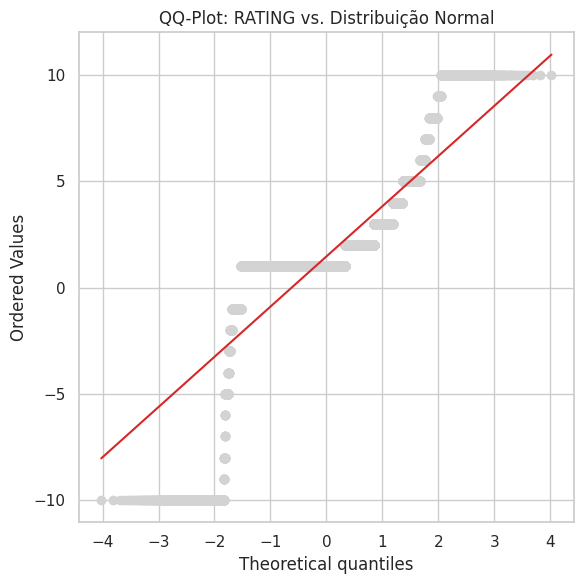

In [22]:
stat_sw, p_valor_sw = stats.shapiro(df["RATING"].dropna())
print(f"Shapiro-Wilk — RATING: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — RATING"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["RATING"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: RATING vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (cinza claro) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [23]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
RATING,0.6617,0.0,True
ANO,0.8807,0.0,True
MES,0.9574,0.0,True
DIA,0.9532,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`RATING`), só pra fixar como essa visualização se lê.

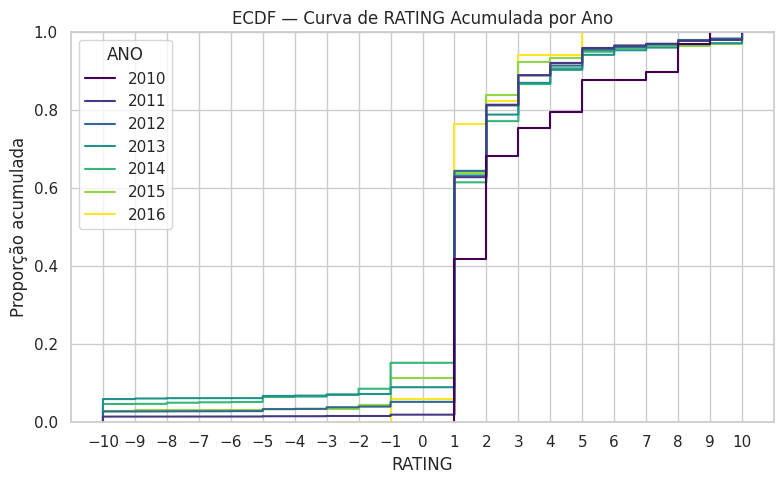

In [24]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="RATING", hue="ANO", palette="viridis")
plt.title("ECDF — Curva de RATING Acumulada por Ano")
plt.xlabel("RATING")
plt.ylabel("Proporção acumulada")
plt.xticks(range(-10, 11, 1))
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração das avaliações desse ano tem a nota até aqui". Onde as curvas se distanciam mais, ali está a faixa de `RATING` onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

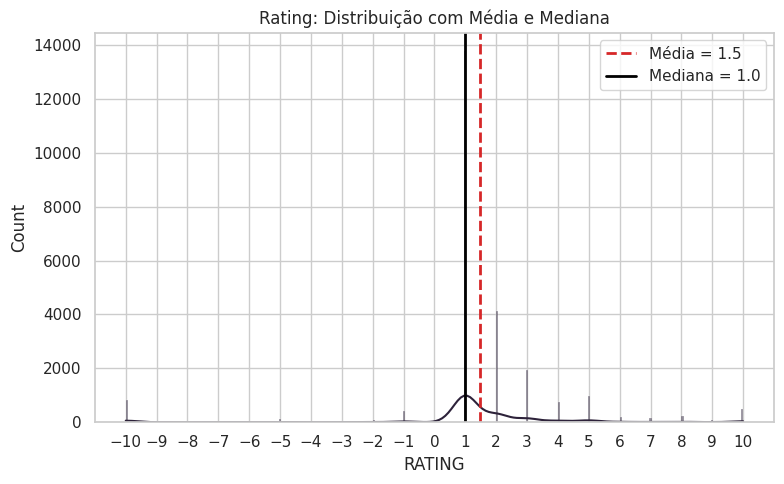

In [25]:
media_rating = df["RATING"].mean()
mediana_rating = df["RATING"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="RATING", kde=True, color=COR_DESTAQUE)
plt.axvline(media_rating, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_rating:.1f}")
plt.axvline(mediana_rating, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_rating:.1f}")
plt.title("Rating: Distribuição com Média e Mediana")
plt.legend()
plt.xticks(range(-10, 11, 1))
plt.tight_layout()
plt.show()

### Dispersão

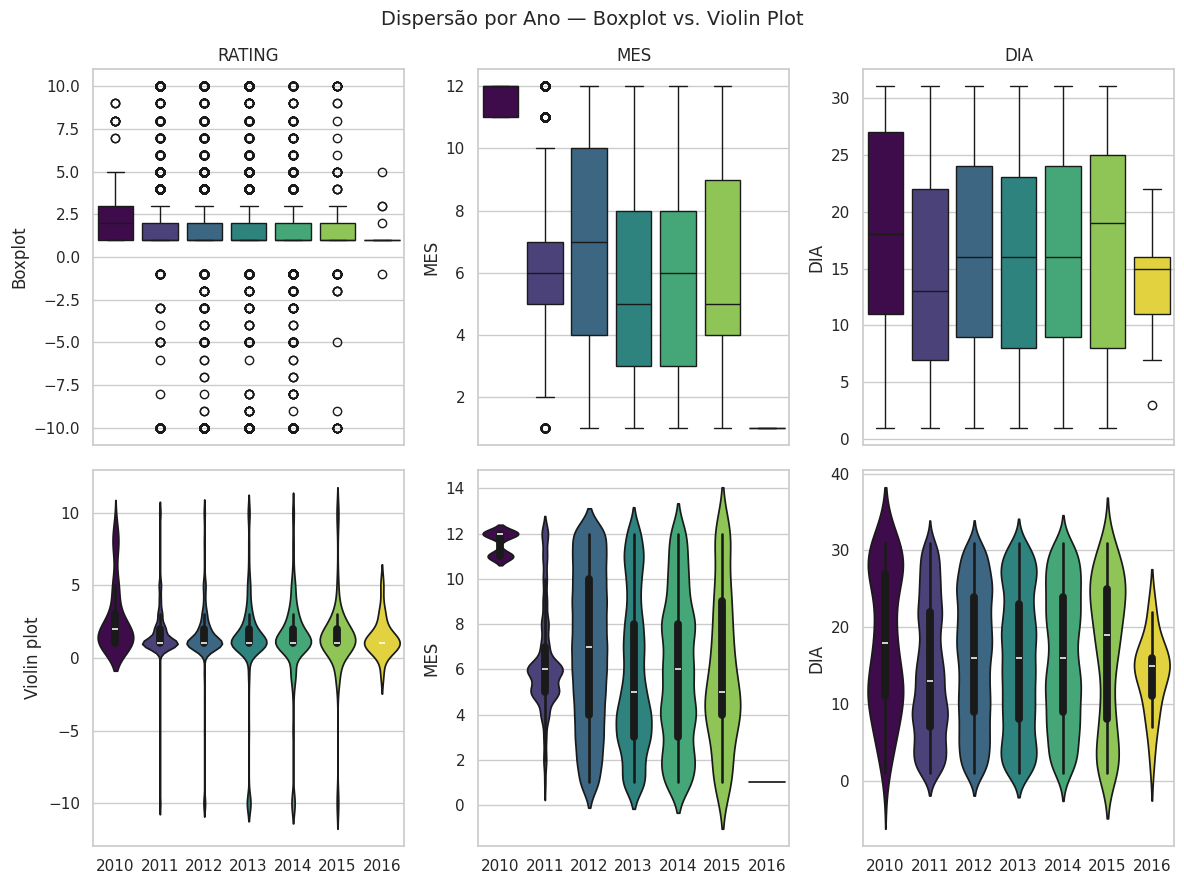

In [26]:
VARS_QUANT_SEM_ANO = ["RATING", "MES", "DIA"]

dispersao = df[VARS_QUANT_SEM_ANO].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT_SEM_ANO].quantile(0.75) - df[VARS_QUANT_SEM_ANO].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por ano"""

fig, axes = plt.subplots(2, len(VARS_QUANT_SEM_ANO), figsize=(4 * len(VARS_QUANT_SEM_ANO), 9), sharex="col")

for i, col in enumerate(VARS_QUANT_SEM_ANO):
    sns.boxplot(data=df, x="ANO", y=col, hue="ANO",
                palette="viridis", legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="ANO", y=col, hue="ANO",
                    palette="viridis", legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Ano — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

#### Análise de Dispersão (IQR) entre os Anos

Ao observarmos os **Boxplots** gerados na célula acima, podemos analisar o comportamento da altura das caixas (que representa o **Intervalo Interquartil - IQR**, ou seja, onde se concentram os 50% centrais dos dados) ao longo dos anos:

1. **`RATING` (Caixas muito baixas e constantes):**
   - O `RATING` possui uma caixa extremamente achatada em quase todos os anos (altura igual a 1 ou muito próxima disso), concentrada entre as notas 1 e 2. O ano de **2010** mostra uma caixa ligeiramente mais deslocada para cima (entre 1 e 3) e **2016** mostra apenas uma linha contínua devido à baixíssima quantidade de dados neste ano específico.

2. **`MES` (Variação nítida de altura):**
   - **2010:** A caixa é **nitidamente a mais baixa (achatada)** de todas, espremida lá no topo (mês 11 e 12). Isso ocorre porque as coletas deste ano começaram apenas no final do ano.
   - **2011:** Mostra uma caixa ligeiramente menor e deslocada para baixo (primeiro semestre).
   - **2012 a 2015:** As caixas são **nitidamente mais altas** (IQR muito maior), cobrindo uma amplitude grande de meses (geralmente do mês 3/4 ao mês 8/10), o que mostra que as transações ocorreram de forma bem distribuída ao longo do ano inteiro.
   - **2016:** Apresenta apenas uma linha reta (mês 1), indicando que os dados cobrem apenas o comecinho do ano.

3. **`DIA` (Comportamento estável):**
   - As caixas para a variável `DIA` possuem uma altura e comportamento **muito estáveis e altos** (cobrindo quase todo o intervalo do dia 8 ao dia 24) entre 2010 e 2015. Isso mostra que as transações ocorrem de forma homogênea ao longo de todos os dias do mês, exceto em **2016** onde a dispersão encolheu consideravelmente devido ao truncamento dos dados.

## 4. Tratamento de Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os outliers das variáveis quantitativas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 3*IQR, Q3 + 3*IQR]`.

In [27]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 3 * iqr, q3 + 3 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
RATING,-2.0,5.0,2182.0
ANO,2005.0,2019.0,0.0
MES,-11.0,24.0,0.0
DIA,-37.0,68.0,0.0


### Visualizando os Outliers

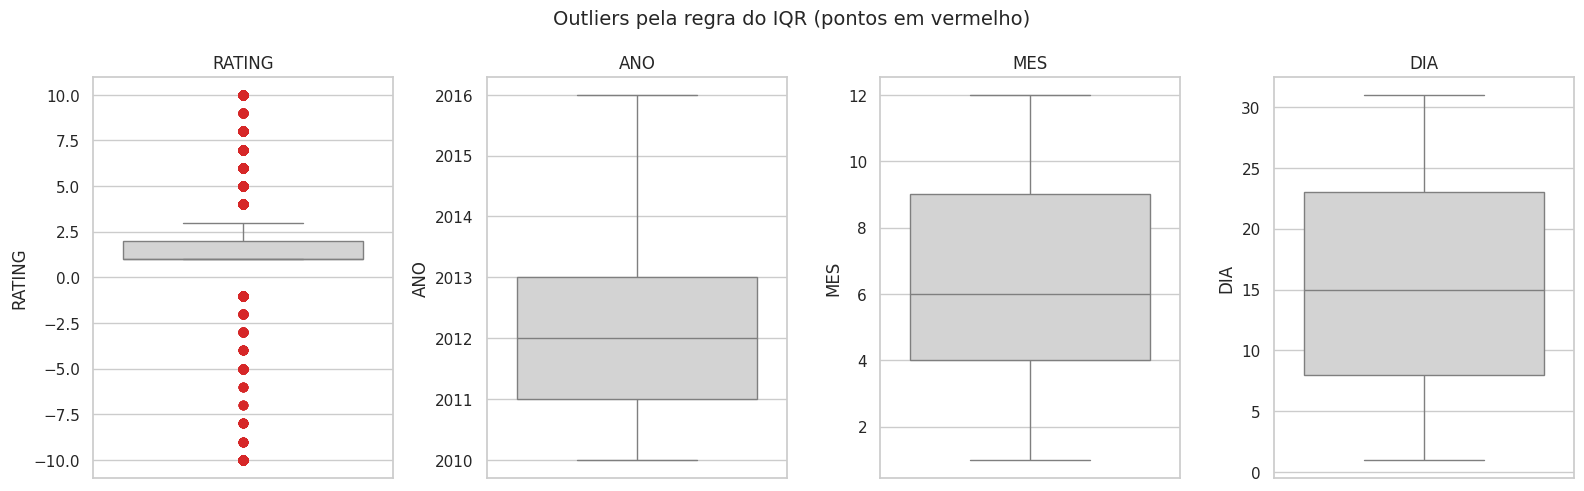

In [28]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Analisando, percebemos que as coluna `ANO` `MES` e `DIA` não possuem outliers, porém a coluna `RATING` sim. Mas, são claramente outliers estatísticos que devem ser mantidos. A maioria das notas dadas estão dentre 0 e 3 e a grande minoria foge disso, aparecendo como outlier, porém não são erros de domínio ou falhas.

### Decidindo o Tratamento dos Outliers

**Não vamos remover**. Pelos valores encontrados, a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a avaliação é real).

## 5. Princípio Relacional

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si.

#### Quantitativa x Quantitativa - Correlação

Temos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

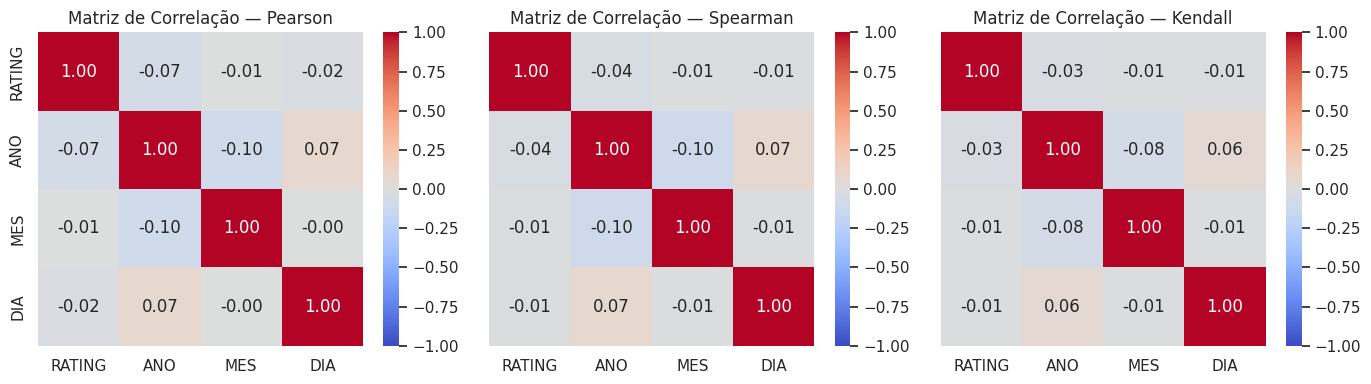

In [29]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

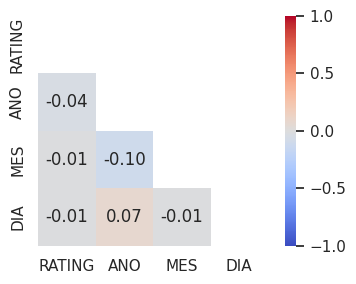

In [30]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

### Análise Comparativa: Pearson vs. Spearman

Comparando as matrizes de correlação calculadas anteriormente, podemos avaliar a consistência entre as duas métricas:

1. **Ausência de Divergência Significativa:**
   - Não há nenhum par de variáveis onde os coeficientes divirjam de forma expressiva. Todos os coeficientes de correlação estão em um patamar extremamente baixo (menores que $0.10$ em módulo) em ambos os métodos.
   - Por exemplo, a relação entre `RATING` e `ANO` é de **-0.07** (Pearson) e **-0.04** (Spearman). Ambas apontam para a mesma direção de associação virtualmente nula.

2. **Relação Praticamente Inexistente:**
   - Se houvesse uma relação fortemente não-linear mas monotônica (por exemplo, um formato de curva suave), o coeficiente de Spearman seria consideravelmente mais alto do que o de Pearson.
   - Como ambos os valores continuam quase zerados para todas as combinações, a conclusão é direta: as variáveis quantitativas analisadas (`RATING`, `ANO`, `MES`, `DIA`) não possuem nenhuma associação forte entre si, seja ela linear ou não-linear.

##### Matriz de Correlação

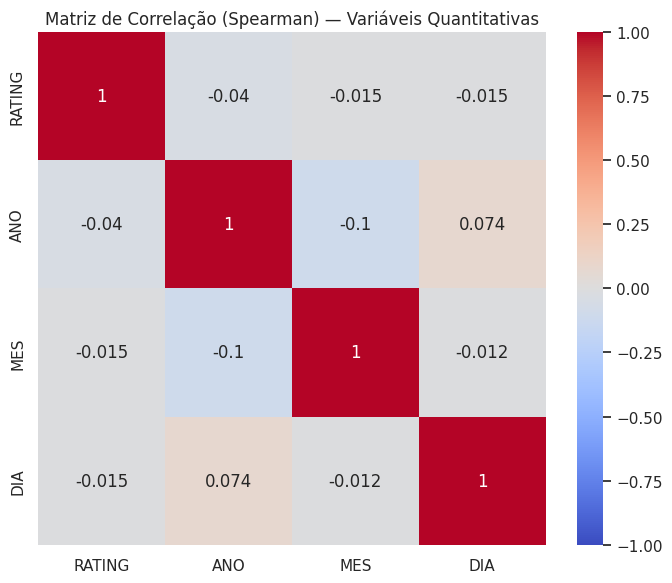

In [31]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

###### Análise de Redundância e Colinearidade

Ao avaliarmos a matriz de correlação de Spearman para identificar possíveis redundâncias (variáveis fortemente correlacionadas que trazem a mesma informação para modelos futuros, tipicamente com $|r| > 0.80$ ou $0.90$):

1. **Ausência Total de Redundância:**
   - A maior correlação em módulo observada em todo o conjunto de variáveis quantitativas é de apenas **-0.10** (entre `ANO` e `MES`).
   - Todas as outras correlações, principalmente as que envolvem a variável de interesse `RATING`, estão próximas de zero ($|r| \le 0.04$).

2. **Conclusão para Modelagem:**
   - **Nenhuma variável é redundante.** Não há necessidade de descartar nenhuma delas por problemas de multicolinearidade.
   - Cada uma das variáveis temporais (`ANO`, `MES`, `DIA`) e a métrica de reputação (`RATING`) carregam informações completamente independentes e ortogonais no dataset.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

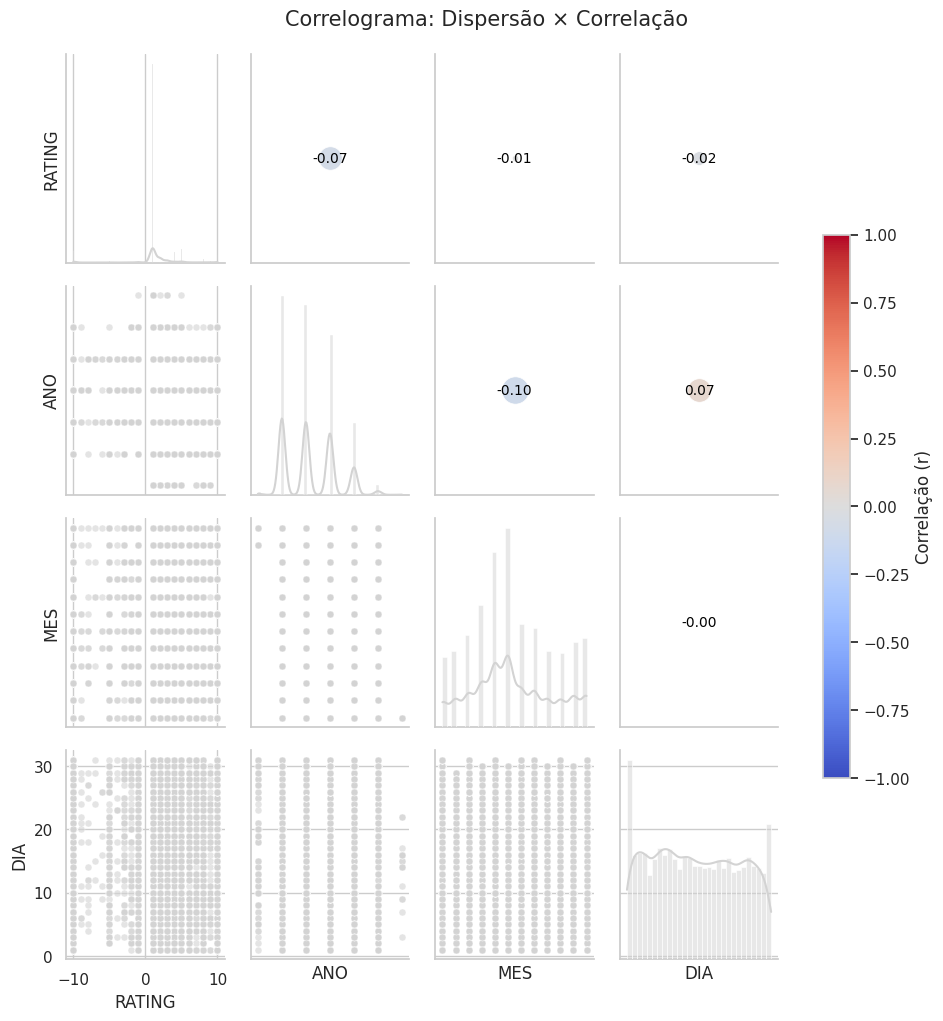

In [32]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)

## 6. Síntese e Principais Conclusões da EDA

Com base em toda a exploração estatística e visual feita ao longo desta análise, podemos consolidar os seguintes aprendizados fundamentais sobre o dataset:

1. **Comportamento das Avaliações (RATING):** Há uma forte assimetria negativa e curtose elevada. A comunidade Bitcoin Alpha é amplamente baseada em confiança mútua, com uma presença esmagadora de notas altamente positivas ($1$, $2$ e $3$). Contudo, notas extremamente negativas (como $-10$) atuam como mecanismos cruciais de denúncia contra maus atores ou fraudes.

2. **Independência Temporal:** Todas as análises bivariadas e correlações calculadas (Pearson, Spearman e Kendall) resultaram em valores nulos ou irrelevantes ($|r| \le 0.10$). Isso prova que o comportamento de atribuição de reputação é independente do fator temporal (ano, mês ou dia em que a transação ocorreu).

3. **Granularidade da Hora:** Identificamos que a variável `HORA` continha apenas registros concentrados em $4h$ e $5h$ da manhã (UTC), o que coincide com a meia-noite (00:00) no fuso horário local da costa leste dos EUA. Essa característica indica que o banco de dados original truncou e agregou as transações em escala diária, o que nos levou a desconsiderar esse campo para análises de tráfego horário.

4. **Outliers Legítimos:** Sob o critério estrito de $3 \times \text{IQR}$, identificamos $2.182$ outliers na variável `RATING`. Estes não representam erros de digitação ou falhas de sistema, mas sim opiniões e notas reais extremas de desconfiança que são de suma importância para mapear a segurança da rede e, por isso, foram mantidos intactos.

5. **Distribuição Temporal dos Dados:** A maior fatia das interações registradas ocorreu de forma homogênea e bem distribuída entre os anos de **2011 e 2014**. Os anos limites (2010, 2015 e 2016) apresentam um volume de dados consideravelmente menor devido ao início e fim das janelas de coleta do dataset original.

## 7. Análise Explanatória

### Pergunta de Pesquisa
> **"Como o ecossistema de confiança do Bitcoin Alpha se comportou ao longo dos anos em termos de reputação e detecção de comportamentos de risco (fraudes)?"**

#### Justificativa da abordagem:
Na análise exploratória anterior, descobrimos que:
1. A grande maioria das avaliações é positiva (com pico em $+1$), mas existem notas extremamente negativas (outliers de $-10$) que servem como mecanismos de defesa da comunidade contra fraudes.
2. As métricas agregadas simples de correlação temporal eram nulas. Portanto, para extrair uma história útil, precisamos cruzar as duas pontas extremas (`+10` como confiança máxima e `-10` como alerta máximo de risco/fraude) ao longo dos anos estruturados de maior atividade (2011 a 2014) para entender a dinâmica de saúde e maturidade da rede.

#### Visualização 1: Evolução da Confiança Máxima vs. Detecção de Risco (2011 - 2014)

**Escolhas de design analítico:**
- **Tipo de Gráfico**: Gráfico de linhas com marcadores para enfatizar a tendência contínua e as proporções ao longo dos anos de maior volume de dados.
- **Atributos Pré-Atentivos**: Uso das cores semânticas estabelecidas. A linha de confiança máxima ($+10$) utiliza a nossa `COR_DESTAQUE` (roxo escuro) para mostrar o padrão esperado de adesão saudável. A linha de alerta máximo ($-10$) utiliza a cor `COR_ALERTA` (vermelho vivo) para chamar a atenção imediata para o volume de fraudes/alertas detectados.
- **Legibilidade**: Grid sutil de fundo, rótulos de dados diretos nas linhas para dispensar a necessidade de ficar olhando para o eixo Y o tempo todo, e escala percentual clara para normalizar o volume total de transações anuais.

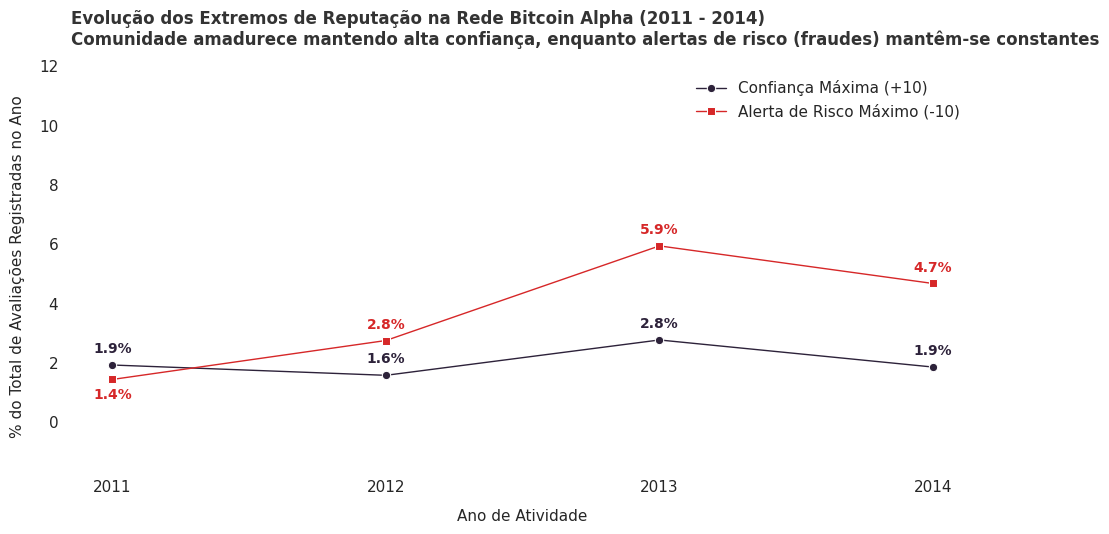

In [33]:
# Filtrando o período principal de atividade identificado na EDA
df_filtered = df[df["ANO"].between(2011, 2014)].copy()

# Calculando as taxas anuais para os extremos de reputação
taxa_extremos = df_filtered.groupby("ANO")["RATING"].agg(
    total_avaliacoes="count",
    confianca_max=lambda x: (x == 10).sum(),
    alerta_max=lambda x: (x == -10).sum()
).reset_index()

taxa_extremos["% Confiança Máxima (+10)"] = (taxa_extremos["confianca_max"] / taxa_extremos["total_avaliacoes"]) * 100
taxa_extremos["% Alerta Máximo (-10)"] = (taxa_extremos["alerta_max"] / taxa_extremos["total_avaliacoes"]) * 100

# Plotagem explanatória
fig, ax = plt.subplots(figsize=(10, 5.5))

# Desenhando as linhas de tendência
sns.lineplot(data=taxa_extremos, x="ANO", y="% Confiança Máxima (+10)",
             marker="o", color=COR_DESTAQUE, linewidth=1, label="Confiança Máxima (+10)", ax=ax)
sns.lineplot(data=taxa_extremos, x="ANO", y="% Alerta Máximo (-10)",
             marker="s", color=COR_ALERTA, linewidth=1, label="Alerta de Risco Máximo (-10)", ax=ax)

# Adicionando anotações com os valores exatos sobre os pontos para leitura imediata
for i, row in taxa_extremos.iterrows():
    # Rótulo da linha de confiança máxima
    ax.annotate(f"{row['% Confiança Máxima (+10)']:.1f}%",
                xy=(row["ANO"], row["% Confiança Máxima (+10)"] + 0.3),
                ha="center", va="bottom", color=COR_DESTAQUE, fontweight="bold", fontsize=10)

    # Rótulo da linha de risco máximo (ajustando especificamente 2011 para ficar abaixo)
    if row["ANO"] == 2011:
        ax.annotate(f"{row['% Alerta Máximo (-10)']:.1f}%",
                    xy=(row["ANO"], row["% Alerta Máximo (-10)"] - 0.3),
                    ha="center", va="top", color=COR_ALERTA, fontweight="bold", fontsize=10)
    else:
        ax.annotate(f"{row['% Alerta Máximo (-10)']:.1f}%",
                    xy=(row["ANO"], row["% Alerta Máximo (-10)"] + 0.3),
                    ha="center", va="bottom", color=COR_ALERTA, fontweight="bold", fontsize=10)

# Ajustes de eixos e títulos
ax.set_title("Evolução dos Extremos de Reputação na Rede Bitcoin Alpha (2011 - 2014)\n"
             "Comunidade amadurece mantendo alta confiança, enquanto alertas de risco (fraudes) mantêm-se constantes",
             fontsize=12, pad=15, loc="left", fontweight="bold", color="#333333")

ax.set_xlabel("Ano de Atividade", fontsize=11, labelpad=10)
ax.set_ylabel("% do Total de Avaliações Registradas no Ano", fontsize=11, labelpad=10)
ax.set_xticks([2011, 2012, 2013, 2014])
ax.set_ylim(-1.5, 12)

# Removendo bordas desnecessárias (spines) para maximizar a proporção dados-tinta
sns.despine(left=True, bottom=True)

# Removendo as linhas de grade do fundo
ax.grid(False)

ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

#### Visualização 2: Identificação de Membros-Chave e Assimetria de Reputação

**Escolhas de design analítico:**
- **Tipo de Gráfico**: Gráfico de barras horizontais empilhadas/lado a lado com as notas médias e volumetria das contas mais avaliadas.
- **História que queremos contar**: Em uma rede Peer-to-Peer sem autoridade central, a comunidade se auto-regula de forma implacável. Analisando as contas (`TARGET`) que mais receberam avaliações na história da plataforma, podemos ver uma clara divisão entre os usuários "Pilares da Comunidade" (altamente confiáveis) e contas que sofreram intervenção coletiva imediata após comportamentos suspeitos.
- **Atributos Pré-Atentivos**: Usamos barras horizontais que facilitam a leitura direta dos IDs dos membros. A cor de destaque (`COR_DESTAQUE`) pinta as contas consolidadas como confiáveis (reputação média positiva), enquanto a cor de alerta (`COR_ALERTA`) é utilizada para rotular instantaneamente a conta que foi massivamente negativada pela comunidade (ID 94).

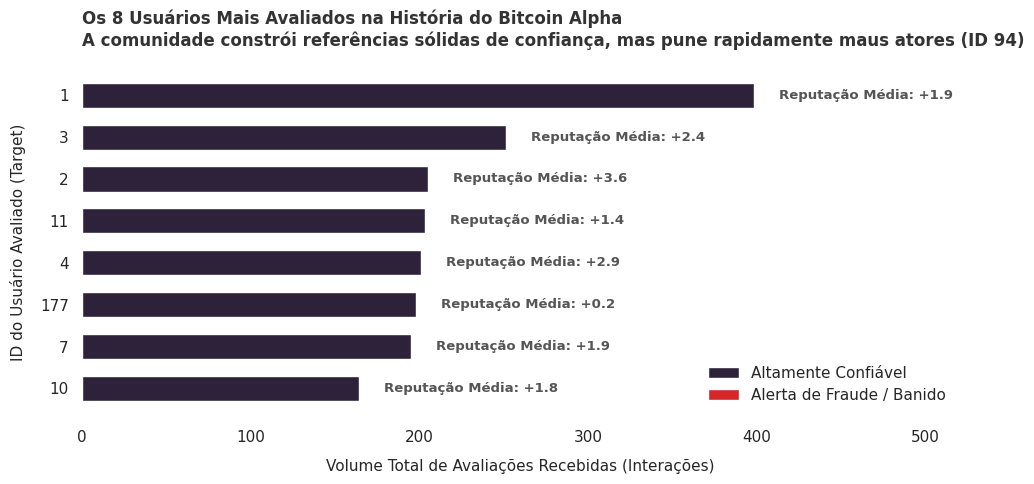

In [34]:
# Identificando os usuários mais avaliados na rede (maior volume de feedback recebido)
top_alvos = df.groupby("TARGET").agg(
    volume_avaliacoes=("RATING", "count"),
    reputacao_media=("RATING", "mean")
).sort_values(by="volume_avaliacoes", ascending=False).head(8).reset_index()

# Definindo cores condicionais: Roxo escuro para reputação positiva confiável, Vermelho para reputação negativa
cores_membros = [COR_DESTAQUE if r >= 0 else COR_ALERTA for r in top_alvos["reputacao_media"]]

# Plotagem
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(y=top_alvos["TARGET"].astype(str), width=top_alvos["volume_avaliacoes"], color=cores_membros, height=0.6)

# Invertendo o eixo Y para ordenar do maior para o menor (de cima para baixo)
ax.invert_yaxis()

# Adicionando anotações textuais explicativas sobre a reputação de cada usuário na própria barra
for bar, reputacao, target_id in zip(bars, top_alvos["reputacao_media"], top_alvos["TARGET"]):
    width = bar.get_width()
    # Texto para o outlier de má reputação
    if reputacao < 0:
        texto_reputacao = f"Reputação Média: {reputacao:.1f}"
        cor_texto = COR_ALERTA
    else:
        texto_reputacao = f"Reputação Média: +{reputacao:.1f}"
        cor_texto = "#555555"

    ax.annotate(texto_reputacao,
                xy=(width + 15, bar.get_y() + bar.get_height()/2),
                va="center", ha="left", fontsize=9.5, fontweight="bold", color=cor_texto)

# Títulos e labels explicativos
ax.set_title("Os 8 Usuários Mais Avaliados na História do Bitcoin Alpha\n"
             "A comunidade constrói referências sólidas de confiança, mas pune rapidamente maus atores (ID 94)",
             fontsize=12, pad=15, loc="left", fontweight="bold", color="#333333")

ax.set_xlabel("Volume Total de Avaliações Recebidas (Interações)", fontsize=11, labelpad=10)
ax.set_ylabel("ID do Usuário Avaliado (Target)", fontsize=11, labelpad=10)
ax.set_xlim(0, 520) # Espaço extra para caber os rótulos de texto confortavelmente

# Removendo totalmente as linhas de grade para limpar o fundo do gráfico
ax.grid(False)

# Adicionando a legenda explicativa com as cores correspondentes
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=COR_DESTAQUE, label="Altamente Confiável"),
    Patch(facecolor=COR_ALERTA, label="Alerta de Fraude / Banido")
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True, facecolor="white", edgecolor="none")

# Limpeza de linhas de borda para foco total na informação principal
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()